# 6.11 - Synthetic markets: how much of a backtest was the strategy, and how much was the path

A backtest replays a strategy on the one history that happened. Its result mixes two things: what the strategy does,
and the luck of that particular sequence of days - which crashes came when, which rallies followed. With only one
history, the two cannot be separated.

*Machine Learning for Trading* (chapter 5) uses **synthetic data** for this: a model of the market, fitted to the
real history, generates many other histories with the same statistical character. Running the strategy's actual
holdings through hundreds of them gives a *distribution* of outcomes instead of one number - its typical result, its
bad years, how often it would have trailed the index.

This notebook:

1. builds three generators of daily returns for the S&P 1500 over 2015-2024, from simple to rich;
2. checks how realistic each is - against the "stylized facts" every real stock market shows, and against a
   classifier trying to tell real months from synthetic ones;
3. runs four strategies of notebook 6.5 - their real month-end books - through 200 synthetic decades from each
   generator;
4. stress-tests them in two scenarios: a year of crisis, and a market 50 % more volatile.

Terms are defined as they come and in the glossary at the end.

In [1]:
import dataclasses
import time

import numpy as np
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.research import store
from equity_research.research import synthetic as syn
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
charts.style()

UNIVERSE, START, END = "SP1500", "2005-01-01", "2024-12-31"
FIRST_TEST, LAST_TEST, TRAIN_YEARS = 2015, 2024, 10
PATHS, SCENARIO_PATHS, FACTORS, SEED = 200, 100, 5, 7
BENCH = -1  # the benchmark's column in the return panel, simulated with the stocks
cache = ResearchCache()
SNAPSHOT = store.data_snapshot(cache)
data = load_universe_data(cache, UNIVERSE, START, END)
dates = data.rebalances
month_ends = dates[(dates.year >= FIRST_TEST) & (dates.year <= LAST_TEST)]
FEATURES = {"universe": UNIVERSE, "start": START, "end": END, "dates": "month ends", "version": 1}
STUDY = FEATURES | {
    "target": "trimmed excess, 1 %",
    "train_years": TRAIN_YEARS,
    "first_test": FIRST_TEST,
    "flat": "ic 0",
}
KEY = STUDY | {"strategies": "P4 v1"}


def slug(name: str) -> str:
    """A strategy's name as a file name, as notebook 6.5 stored it."""
    return "".join(c if c.isalnum() else "_" for c in name)


STRATEGIES = [
    "Composite | long-short | mean_variance",
    "Composite | long-short | equal",
    "GBM Optuna (6.4) | long-short | mean_variance",
    "Logistic (6.3) | long-only | mean_variance",
]
books, costs, gross = {}, {}, {}
for name in STRATEGIES:
    book = store.load("strategy", f"book-{slug(name)}", KEY, snapshot=SNAPSHOT)
    daily = store.load("strategy", f"daily-{slug(name)}", KEY, snapshot=SNAPSHOT)
    assert book is not None and daily is not None, "run notebook 6.5 first"
    book.index = pd.DatetimeIndex(book.index)
    daily.index = pd.DatetimeIndex(daily.index)
    books[name], gross[name] = book, daily["gross"]
    # each month's costs as the backtest charged them - trading and, for short books, borrowing: gross less net
    costs[name] = (
        syn.month_compound(daily[["gross"]], month_ends)["gross"]
        - syn.month_compound(daily[["net"]], month_ends)["net"]
    )
long_only = {n: n.split(" | ")[1] == "long-only" for n in STRATEGIES}

# the market: every listing that was an index member at some point in the test years, and the benchmark
window = data.returns.loc[month_ends[0] : month_ends[-1]]
members = data.members.reindex(index=window.index, columns=window.columns, fill_value=False).astype(bool)
panel = window.loc[:, members.any()].copy()
panel[BENCH] = data.benchmark.reindex(window.index)
print(f"{panel.shape[0]:,} days x {panel.shape[1] - 1:,} listings, {month_ends[0]:%Y-%m} to {month_ends[-1]:%Y-%m}")

left out 887 facts of 2 companies in ['GBP']


2,497 days x 2,284 listings, 2015-01 to 2024-12


## Step 0 - the books replay the backtest

The stress test holds each strategy's real month-end weights through each month, on whatever returns a path supplies.
That is simpler than notebook 6.5's daily backtest (which lets weights drift and trades only at month ends), so first
a check: replayed on the *real* returns, do the books earn what the backtest earned before costs?

In [2]:
real_monthly = syn.month_compound(panel, month_ends)
check = {}
for name in STRATEGIES:
    replay = syn.book_returns(books[name], panel, month_ends)
    backtest = syn.month_compound(gross[name].to_frame("g"), month_ends)["g"]
    daily = store.load("strategy", f"daily-{slug(name)}", KEY, snapshot=SNAPSHOT)
    daily.index = pd.DatetimeIndex(daily.index)
    net = syn.month_compound(daily[["net"]], month_ends)["net"]
    check[name] = {
        "gross: replay": replay.mean(),
        "gross: backtest": backtest.mean(),
        "correlation": replay.corr(backtest),
        "net: replay less costs": (replay - costs[name]).mean(),
        "net: backtest": net.mean(),
    }
display(pd.DataFrame(check).T.style.format("{:+.2%}").format({"correlation": "{:.3f}"}))

,gross: replay,gross: backtest,correlation,net: replay less costs,net: backtest
Composite | long-short | mean_variance,0.009299,0.009299,1.000,0.006444,0.006444
Composite | long-short | equal,0.005109,0.005109,1.000,0.002517,0.002517
GBM Optuna (6.4) | long-short | mean_variance,0.020133,0.020133,1.000,0.011087,0.011087
Logistic (6.3) | long-only | mean_variance,0.015169,0.015169,1.000,0.012988,0.012988


## Step 1 - three generators, and how realistic each is

* **Block bootstrap** - cut the real decade into blocks of about a month (random lengths) and shuffle them. Every
  stock's return of a day moves together, so the day's correlations and fat tails are real; what is lost is anything
  slower than a block, such as a long bull market.
* **Factor model with GARCH** - the market is five *factors* (the principal components of the returns: the market,
  then the main styles), each with volatility that clusters (a GARCH(1,1) process: a turbulent day makes the next one
  likely turbulent) and fat-tailed shocks (Student-t), plus each stock's own noise. Every path is new, not reshuffled.
* **Regime model** - the same factors, but the market switches between a *calm* and a *turbulent* state (a hidden
  Markov chain, fitted to the first factor), each with its own means, volatilities and correlations - in turbulence,
  stocks fall together.

Each must reproduce the **stylized facts** of real markets (Cont, 2001): fat tails (excess kurtosis above 0),
returns that do not predict the next day's (autocorrelation near 0), volatility that clusters (absolute returns *are*
autocorrelated, still at 20 days), the leverage effect (falls raise later volatility: a negative correlation), and
how strongly stocks move together. Five paths per generator are compared with the real decade.

In [3]:
t0 = time.time()
generators = {
    "block bootstrap": syn.fit_bootstrap(panel, mean_block=21),
    "factor GARCH": syn.fit_factor_garch(panel, factors=FACTORS),
    "regime switching": syn.fit_regime(panel, factors=FACTORS),
}
print(f"fitted in {time.time() - t0:.0f}s")
garch = generators["factor GARCH"]
print("GARCH(1,1)-t of each factor: persistence (alpha + beta) and tail (degrees of freedom)")
display(
    pd.DataFrame(
        {
            f"f{i + 1}": {
                "alpha + beta": m.alpha + m.beta,
                "nu": m.nu,
                "yearly vol": np.sqrt(m.omega / max(1e-12, 1 - m.alpha - m.beta) * 252),
            }
            for i, m in enumerate(garch.factor_models)
        }
    ).T.style.format("{:.2f}")
)
regimes = generators["regime switching"].regimes
print(
    f"regimes: calm days stay calm with probability {regimes.transition[0, 0]:.3f}, turbulent ones turbulent "
    f"with {regimes.transition[1, 1]:.3f}; turbulent {regimes.start[1]:.0%} of days; market factor's yearly vol "
    f"{np.sqrt(regimes.covs[0][0, 0] * 252):.1%} calm, {np.sqrt(regimes.covs[1][0, 0] * 252):.1%} turbulent"
)

fitted in 11s
GARCH(1,1)-t of each factor: persistence (alpha + beta) and tail (degrees of freedom)


,alpha + beta,nu,yearly vol
f1,0.99,8.59,0.25
f2,0.99,8.24,0.10
f3,0.99,10.69,0.08
f4,0.97,7.96,0.06
f5,0.94,6.89,0.06


regimes: calm days stay calm with probability 0.982, turbulent ones turbulent with 0.925; turbulent 19% of days; market factor's yearly vol 15.4% calm, 43.5% turbulent


In [4]:
rng = np.random.default_rng(SEED)
samples = {g: [gen.sample(rng) for _ in range(5)] for g, gen in generators.items()}
facts = {"real": syn.stylized_facts(panel)}
for g, paths in samples.items():
    facts[g] = pd.concat([syn.stylized_facts(p) for p in paths], axis=1).mean(axis=1)
facts_table = pd.DataFrame(facts)
facts_table.loc["discriminator accuracy"] = [np.nan] + [syn.discriminator_score(panel, samples[g]) for g in samples]
display(facts_table.style.format("{:.3f}", na_rep="-"))

,real,block bootstrap,factor GARCH,regime switching
kurtosis,19.603,17.165,5.804,8.290
acf_ret_1,-0.038,-0.032,-0.000,0.001
acf_abs_1,0.227,0.197,0.042,0.097
acf_abs_20,0.102,0.034,0.027,0.007
leverage_5,-0.057,-0.053,0.001,-0.022
mean_corr,0.296,0.288,0.275,0.287
first_pc,0.275,0.268,0.255,0.267
market_kurtosis,12.911,10.890,4.370,4.538
market_acf_abs_1,0.362,0.310,0.237,0.248
market_vol,0.218,0.196,0.205,0.210


## Step 2 - the strategies on 200 synthetic decades

Each path is a full 2015-2024 of daily returns for every listing and the benchmark. On each, every strategy holds its
real month-end book, pays the costs it paid in the backtest that month, and its monthly returns compound into a
decade.

**What a path keeps and what it breaks.** A book chosen at a month end was chosen to do well *in the month that
followed*. On a synthetic path that month's returns are different ones - another month's (bootstrap) or new draws
(the factor models) - so the link between a forecast and its month is broken. What survives is everything standing:
the book's exposure to the market and to the styles, its concentration, its costs. The paths therefore show what the
books would have earned **without their forecasting skill** - a "no-skill" distribution - and the risks they carry
whatever the forecasts. Where the real decade falls in that distribution is the evidence for skill: a real result
above nearly all the paths came from something the paths do not have.

Across the 200 paths:

* **CAGR** - the yearly growth rate: the median path, and the 5th and 95th percentiles (the bad and good tails);
* **max drawdown** - the worst fall from a peak: the median, and the 95th percentile (one path in twenty is worse);
* **p_loss** - the share of paths on which the strategy lost money over the decade;
* for the long-only strategy, **active** (its CAGR minus the benchmark's on the same path) and **p_trail**, the
  share of paths on which it trailed the benchmark;
* **real beats** - the share of paths whose CAGR the real decade's beat (for the long-only strategy, whose active
  return it beat).

The real decade is shown first for comparison.

In [5]:
def run_paths(gen, n, rng):
    """Each strategy's net monthly returns, and the benchmark's, on n paths: {name: month x path}."""
    out = {name: {} for name in [*STRATEGIES, "benchmark"]}
    for k in range(n):
        path = gen.sample(rng)
        for name in STRATEGIES:
            out[name][k] = syn.book_returns(books[name], path, month_ends) - costs[name]
        out["benchmark"][k] = syn.month_compound(path[[BENCH]], month_ends)[BENCH]
    return {name: pd.DataFrame(v) for name, v in out.items()}


def cagr(monthly):
    """Yearly growth rate of each column of monthly returns."""
    return (1 + monthly).prod() ** (12 / len(monthly)) - 1


def summary(runs, real=None):
    """Outcomes of each strategy across paths, the benchmark's own, and the share of paths the real decade beat.

    Long-only strategies are judged against the benchmark on the same path.
    """
    rows = {}
    for name in STRATEGIES:
        rows[name] = syn.outcomes(runs[name], runs["benchmark"] if long_only[name] else None)
        if real is not None:
            paths, actual = cagr(runs[name]), float(cagr(real[name]).iloc[0])
            if long_only[name]:
                paths = paths - cagr(runs["benchmark"])
                actual -= float(cagr(real["benchmark"]).iloc[0])
            rows[name]["real beats"] = float((paths < actual).mean())
    rows["benchmark (SPTM)"] = syn.outcomes(runs["benchmark"])
    return pd.DataFrame(rows).T


real = {name: (syn.book_returns(books[name], panel, month_ends) - costs[name]).to_frame(0) for name in STRATEGIES}
real["benchmark"] = real_monthly[[BENCH]].rename(columns={BENCH: 0})
FORMAT = {c: "{:+.1%}" for c in ["cagr_median", "cagr_p05", "cagr_p95", "active_median"]} | {
    c: "{:.0%}" for c in ["max_dd_median", "max_dd_p95", "p_loss", "p_trail", "real beats"]
}
print("the real decade (one path)")
display(
    summary(real)[["cagr_median", "max_dd_median", "active_median"]]
    .rename(columns={"cagr_median": "CAGR", "max_dd_median": "max drawdown", "active_median": "active"})
    .style.format({"CAGR": "{:+.1%}", "max drawdown": "{:.0%}", "active": "{:+.1%}"}, na_rep="-")
)
t0 = time.time()
runs = {}
for g, gen in generators.items():
    runs[g] = run_paths(gen, PATHS, np.random.default_rng(SEED))
    print(f"{g}: {PATHS} paths in {time.time() - t0:.0f}s")
    display(summary(runs[g], real).style.format(FORMAT, na_rep="-"))

the real decade (one path)


,CAGR,max drawdown,active
Composite | long-short | mean_variance,+7.4%,21%,-
Composite | long-short | equal,+2.4%,30%,-
GBM Optuna (6.4) | long-short | mean_variance,+10.9%,52%,-
Logistic (6.3) | long-only | mean_variance,+14.7%,27%,+1.6%
benchmark (SPTM),+13.1%,24%,-


block bootstrap: 200 paths in 222s


,active_median,cagr_median,cagr_p05,cagr_p95,max_dd_median,max_dd_p95,p_loss,p_trail,real beats
Composite | long-short | mean_variance,-,+1.4%,-3.4%,+7.1%,25%,44%,36%,-,96%
Composite | long-short | equal,-,+0.5%,-4.2%,+5.2%,26%,46%,46%,-,72%
GBM Optuna (6.4) | long-short | mean_variance,-,-7.2%,-15.9%,+1.7%,64%,85%,92%,-,100%
Logistic (6.3) | long-only | mean_variance,+0.2%,+13.0%,+3.0%,+23.6%,28%,52%,2%,49%,69%
benchmark (SPTM),-,+13.1%,+2.9%,+22.8%,26%,47%,0%,-,-


factor GARCH: 200 paths in 493s


,active_median,cagr_median,cagr_p05,cagr_p95,max_dd_median,max_dd_p95,p_loss,p_trail,real beats
Composite | long-short | mean_variance,-,-4.3%,-9.2%,+0.9%,41%,64%,92%,-,100%
Composite | long-short | equal,-,-5.8%,-10.3%,-0.8%,47%,67%,97%,-,100%
GBM Optuna (6.4) | long-short | mean_variance,-,-13.2%,-21.5%,-3.9%,78%,93%,98%,-,100%
Logistic (6.3) | long-only | mean_variance,-4.6%,+9.6%,-0.3%,+22.0%,32%,56%,6%,90%,94%
benchmark (SPTM),-,+13.9%,+3.5%,+26.3%,24%,46%,2%,-,-


regime switching: 200 paths in 762s


,active_median,cagr_median,cagr_p05,cagr_p95,max_dd_median,max_dd_p95,p_loss,p_trail,real beats
Composite | long-short | mean_variance,-,-4.0%,-8.6%,+1.4%,42%,61%,89%,-,100%
Composite | long-short | equal,-,-5.3%,-9.3%,-1.0%,46%,63%,98%,-,100%
GBM Optuna (6.4) | long-short | mean_variance,-,-12.2%,-20.7%,-3.4%,79%,92%,100%,-,100%
Logistic (6.3) | long-only | mean_variance,-4.4%,+9.3%,-1.4%,+22.7%,34%,60%,9%,90%,97%
benchmark (SPTM),-,+14.2%,+2.3%,+25.1%,27%,49%,2%,-,-


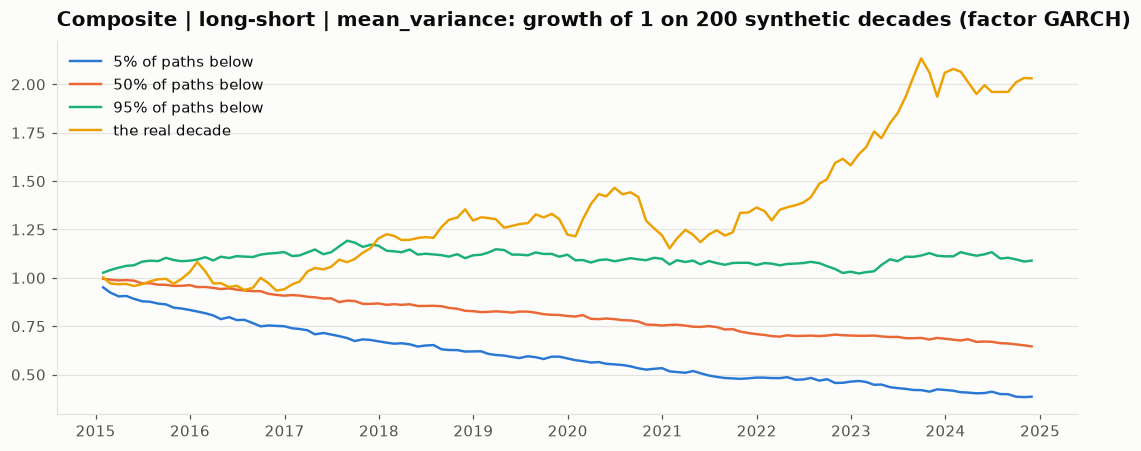

In [6]:
best = "Composite | long-short | mean_variance"
wealth = (1 + runs["factor GARCH"][best]).cumprod()
fan = {f"{q:.0%} of paths below": wealth.quantile(q, axis=1) for q in (0.05, 0.5, 0.95)}
fan["the real decade"] = (1 + real[best][0]).cumprod()
fig = charts.lines(fan, f"{best}: growth of 1 on 200 synthetic decades (factor GARCH)")

## Step 3 - stress scenarios

* **A year of crisis** - the regime model held in its turbulent state for the first 252 trading days of every path
  (2015 in the calendar of the paths), then left to switch as fitted.
* **A rougher market** - the factor GARCH model with every factor's and every stock's volatility 50 % higher.

The books and costs are unchanged: what a scenario tests is the holdings, not a strategy that would have adapted.

In [7]:
crisis = dataclasses.replace(generators["regime switching"], force_turbulent=(0, 252))
rough = dataclasses.replace(generators["factor GARCH"], vol_scale=1.5)
scenario_runs = {}
for label, gen in (("a year of crisis", crisis), ("volatility +50%", rough)):
    scenario_runs[label] = run_paths(gen, SCENARIO_PATHS, np.random.default_rng(SEED + 1))
    print(label)
    display(summary(scenario_runs[label]).style.format(FORMAT, na_rep="-"))

a year of crisis


,active_median,cagr_median,cagr_p05,cagr_p95,max_dd_median,max_dd_p95,p_loss,p_trail
Composite | long-short | mean_variance,-,-4.5%,-9.5%,+0.1%,45%,67%,94%,-
Composite | long-short | equal,-,-5.5%,-9.6%,-1.4%,49%,63%,99%,-
GBM Optuna (6.4) | long-short | mean_variance,-,-13.4%,-22.9%,-1.3%,82%,93%,96%,-
Logistic (6.3) | long-only | mean_variance,-4.8%,+7.0%,-6.0%,+18.3%,42%,64%,18%,88%
benchmark (SPTM),-,+10.3%,+1.7%,+23.3%,34%,52%,1%,-


volatility +50%


,active_median,cagr_median,cagr_p05,cagr_p95,max_dd_median,max_dd_p95,p_loss,p_trail
Composite | long-short | mean_variance,-,-5.2%,-11.8%,+2.4%,51%,75%,90%,-
Composite | long-short | equal,-,-5.8%,-13.3%,+0.5%,51%,77%,93%,-
GBM Optuna (6.4) | long-short | mean_variance,-,-15.4%,-30.4%,+2.8%,88%,99%,92%,-
Logistic (6.3) | long-only | mean_variance,-5.0%,+6.7%,-7.8%,+26.7%,52%,84%,22%,85%
benchmark (SPTM),-,+12.6%,-4.2%,+28.9%,42%,73%,11%,-


## Findings

**In short: the strategies' real results came from their month-by-month stock selection, not from luck in the path
or from what they stood exposed to.** On the factor models' paths, which keep a book's exposures but not its
selection, every long-short book loses money on 89-100 % of decades and the long-only book trails the index on 90 %;
the real decade beat 94-100 % of those paths for all four. That supports the out-of-sample ICs of 6.3-6.4. It does
not undo the selection problem of 6.5-6.6: these four were chosen from 44 after seeing the decade.

**1. The books replay the backtest exactly (step 0).** Held on the real returns with each month's real costs
(trading, and borrowing for the short side), the books earn what notebook 6.5's backtest earned: the same mean
monthly return, gross and net, for all four, and a correlation of 1.000.

**2. Fidelity: the bootstrap is the most realistic, the factor models miss single stocks' clustering (step 1).**

| | real | block bootstrap | factor GARCH | regime switching |
|---|---|---|---|---|
| excess kurtosis of a stock's daily returns | 19.6 | 17.2 | 5.8 | 8.3 |
| volatility clustering, 1 day / 20 days | 0.23 / 0.10 | 0.20 / 0.03 | 0.04 / 0.03 | 0.10 / 0.01 |
| leverage effect (5 days) | -0.06 | -0.05 | 0.00 | -0.02 |
| average correlation between stocks | 0.30 | 0.29 | 0.28 | 0.29 |
| classifier telling real months from synthetic | - | 49 % | 78 % | 68 % |

* **Block bootstrap** - a classifier cannot tell its months from real ones (49 %, chance). It keeps a day's fat
  tails, co-movement and the leverage effect, because those are real days, but not volatility's persistence beyond
  a month (0.03 at 20 days, against 0.10).
* **Factor GARCH** - its five factors cluster as the market does (persistence 0.94-0.99), but each stock's own noise
  is drawn independently day by day, so a single stock's volatility barely clusters (0.04 against 0.23), its tails
  are thin (5.8), and a symmetric GARCH has no leverage effect. A classifier spots its months 78 % of the time.
* **Regime switching** - a turbulent state on 19 % of days, in which the market factor's volatility is 43.5 % a year
  against 15.4 % in calm (calm days stay calm with probability 0.982 a day, turbulent ones turbulent with 0.925).
  The switches add some clustering, tails and a weak leverage effect: 68 %.

All three match how strongly stocks move together (0.28-0.29 against 0.30), the property that matters most for a
portfolio's risk.

**3. What the books earn without their skill (step 2).** A synthetic path keeps a book's standing exposures - to the
market, to styles, to the decade's winners - but breaks the link between a month's forecast and that month's
returns. The block bootstrap keeps one more thing: a stock that did well over the whole decade still does on
average, since every path reuses the decade's days.

| Strategy | real CAGR | bootstrap: median (5th-95th) | factor GARCH: median | regime: median | real beats (bootstrap / GARCH / regime) |
|---|---|---|---|---|---|
| Composite, long-short, mean-variance | +7.4 % | +1.4 % (-3.4 to +7.1) | -4.3 % | -4.0 % | 96 % / 100 % / 100 % |
| Composite, long-short, equal | +2.4 % | +0.5 % (-4.2 to +5.2) | -5.8 % | -5.3 % | 72 % / 100 % / 100 % |
| GBM Optuna, long-short, mean-variance | +10.9 % | -7.2 % (-15.9 to +1.7) | -13.2 % | -12.2 % | 100 % / 100 % / 100 % |
| Logistic, long-only, mean-variance: active | +1.6 % | +0.2 % (median) | -4.6 % | -4.4 % | 69 % / 94 % / 97 % |

* **Long-short books** - without month-specific selection, costs and borrowing (3.4 % a year for the composite's
  mean-variance book, 11 % for gradient boosting's) sink them: they lose money on 36-100 % of paths. The real decade
  beat every factor-model path for all three, and 96-100 % of bootstrap paths for the two mean-variance books. Their
  returns came from choosing the right stocks for the next month - what 6.3-6.4 measured as IC - not from a lucky
  path or a standing tilt. The composite's equal-weighted book is the exception: it beat only 72 % of bootstrap
  paths, so much of its small return came from holding stocks that did well over the whole decade.
* **The long-only book** - on the factor models its standing exposures and its costs (2.6 % a year) leave it about
  4.5 % a year behind the index: it trailed on 90 % of paths. Its real +1.6 % beat 94-97 % of them, so its
  selection earned about 6 points a year to finish 1.6 ahead. Against the bootstrap, which keeps the decade's
  winners, its median is +0.2 % and the real result beat only 69 % of paths: next to what the decade's own days
  could produce, its edge is not distinctive.
* **Drawdowns** - the worst twentieth of paths shows falls the real decade did not: 44-67 % for the composite's
  long-short books without skill, 85-93 % for gradient boosting's, 52-60 % for the long-only book (the index: 46-49 %).

**4. Stress scenarios (step 3).** With the books and costs unchanged:

* **A year of crisis** (the turbulent state for all of the first year) - the long-only book's median growth falls
  from +9.3 % to +7.0 % a year, its worst-twentieth drawdown is 64 % against the index's 52 %, and 18 % of paths
  lose money over the decade.
* **Volatility +50 %** - its worst-twentieth drawdown reaches 84 % (the index: 73 %); gradient boosting's long-short
  book falls 99 % in the worst twentieth.

The long-only book's concentrated mean-variance weights make its bad tail worse than the index's in both scenarios.

**5. What this adds, and what it does not.** The synthetic paths answer one question cleanly: given the books, was
the result luck in the sequence of events? For the mean-variance books, no - the real decade sits at or beyond the
top of what their exposures alone produce. That is a test of each strategy on its own. It does not correct for
having chosen these four from 44 (6.6's deflated ratios and studentised Reality Check still apply), nor for the
composite's features having been picked with 2005-2024 in view; and the books carry concentration that turns a
rough market into deep drawdowns.

## Glossary

* **Synthetic data** - returns generated by a model fitted to real ones: the same statistical character, a
  different sequence of events.
* **Path** - one synthetic history, here ten years of daily returns for every listing.
* **Stylized facts** - statistical properties found in nearly every real market: fat tails, volatility clustering,
  no predictability of returns from yesterday's, the leverage effect, co-movement.
* **Excess kurtosis** - how much fatter than a normal distribution's the tails are (0 for a normal).
* **Volatility clustering** - large moves follow large moves: absolute returns are autocorrelated.
* **Leverage effect** - falls are followed by higher volatility than rises of the same size.
* **Block bootstrap** - resampling a history in blocks of consecutive days, to keep short-range dependence.
* **GARCH(1,1)** - a model in which today's variance is a weighted sum of a constant, yesterday's squared shock
  and yesterday's variance; alpha + beta near 1 means turbulence persists.
* **Student-t** - a distribution with fatter tails than the normal; fewer degrees of freedom (nu), fatter tails.
* **Hidden Markov model** - a model in which an unseen state (calm, turbulent) switches with fixed probabilities and
  each state has its own distribution of returns; fitted by the Baum-Welch algorithm.
* **Discriminator accuracy** - how often a classifier tells real months from synthetic ones; 50 % means it cannot.
* **Drawdown** - the fall from the highest value reached so far.